# Klasifikasi Tujuh Jenis Lesi Kulit Menggunakan CNN dengan Transfer Learning

**Dataset:** [Skin Cancer MNIST: HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000)  
**Model:** MobileNetV2 (transfer learning)  
**Deploy:** Website (Next.js, Echo, dan FastAPI)

### Kompleksitas Masalah (A.1)
- **Mengapa kompleks (A.1.a):** kelas sangat tidak seimbang (58,3 : 1), beberapa jenis lesi tampak mirip, kondisi citra bervariasi, dan satu lesi dapat memiliki beberapa citra.
- **Tantangan utama (A.1.b):** mengenali kelas minoritas, tidak hanya mengandalkan kelas terbesar, dan mencegah kebocoran data antarsplit.
- **Pengembangan dari Tugas Proyek 2 (A.1.c):** *[isi bagian yang ditambah, diperbaiki, atau diganti]*

## **Import Library**

In [ ]:
import os
import glob
import io
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
import keras
import kagglehub

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Konfigurasi**

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42
EPOCHS_HEAD = 8
EPOCHS_FINE = 12
UNFREEZE_LAST = 30
CONFIDENCE_THRESHOLD = 0.5

OUTPUT_DIR = '/content/drive/My Drive/Colab Notebooks/Matkul_DeepLearning/UTS/models'
os.makedirs(OUTPUT_DIR, exist_ok=True)

keras.utils.set_random_seed(SEED)

## **Data Loading**
Dataset diunduh dengan `kagglehub`, jadi tidak perlu mengunggah `kaggle.json`.

In [ ]:
DATA_DIR = os.environ.get('HAM_DATA_DIR') or kagglehub.dataset_download('kmader/skin-cancer-mnist-ham10000')
print('Lokasi dataset:', DATA_DIR)
print(os.listdir(DATA_DIR))

100%|██████████| 5.20G/5.20G [04:41<00:00, 19.8MB/s]

Extracting files...


Lokasi dataset: /root/.cache/kagglehub/datasets/kmader/skin-cancer-mnist-ham10000/versions/2
['ham10000_images_part_2', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_RGB.csv', 'hmnist_8_8_L.csv', 'ham10000_images_part_1', 'HAM10000_images_part_1', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv', 'HAM10000_images_part_2']


In [ ]:
df = pd.read_csv(os.path.join(DATA_DIR, 'HAM10000_metadata.csv'))

image_paths = {}
for path in sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.jpg'), recursive=True)):
    image_id = os.path.splitext(os.path.basename(path))[0]
    image_paths.setdefault(image_id, path)

df['path'] = df['image_id'].map(image_paths)
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/root/.cache/kagglehub/datasets/kmader/skin-ca...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/root/.cache/kagglehub/datasets/kmader/skin-ca...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/root/.cache/kagglehub/datasets/kmader/skin-ca...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/root/.cache/kagglehub/datasets/kmader/skin-ca...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/root/.cache/kagglehub/datasets/kmader/skin-ca...


## **Data Understanding**
HAM10000 berisi citra dermatoskopi nyata (*real-world*), bukan data sintetis. Setiap citra memiliki satu label diagnosis pada kolom `dx`.

| Kolom | Arti |
|---|---|
| `lesion_id` | ID lesi; satu lesi bisa memiliki beberapa citra |
| `image_id` | ID citra dan nama file |
| `dx` | Label kelas yang diprediksi |
| `dx_type` | Cara penetapan diagnosis |
| `age`, `sex`, `localization` | Usia, jenis kelamin, dan lokasi lesi |

Model hanya memakai citra sebagai input. Metadata digunakan untuk analisis data.

In [ ]:
CLASS_NAMES = {
    'akiec': 'Actinic keratoses',
    'bcc': 'Basal cell carcinoma',
    'bkl': 'Benign keratosis-like lesions',
    'df': 'Dermatofibroma',
    'mel': 'Melanoma',
    'nv': 'Melanocytic nevi',
    'vasc': 'Vascular lesions',
}
CLASSES = sorted(CLASS_NAMES)
NUM_CLASSES = len(CLASSES)

print('Jumlah citra:', len(df))
print('Jumlah lesi :', df['lesion_id'].nunique())
print('Jumlah kelas:', NUM_CLASSES)
with Image.open(df['path'].iloc[0]) as img:
    print('Contoh citra:', img.format, img.size, img.mode)
df.info()

Jumlah citra: 10015
Jumlah lesi : 7470
Jumlah kelas: 7
Contoh citra: JPEG (600, 450) RGB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
 7   path          10015 non-null  object 
dtypes: float64(1), object(7)
memory usage: 626.1+ KB


**Penjelasan (A.2):** Sumber data adalah Kaggle (tautan di atas). Dataset berisi 10.015 citra JPEG RGB berukuran 600×450 dari 7.470 lesi dan 7 kelas. Dataset bersifat *real-world* karena berasal dari citra dermatoskopi klinis. Kompleksitasnya berasal dari ketidakseimbangan kelas, kemiripan antarkelas, variasi kondisi citra, dan banyak citra dari lesi yang sama.

In [ ]:
print('Nilai kosong per kolom:')
print(df.isna().sum())
print()
print('Nilai unknown pada sex         :', (df['sex'] == 'unknown').sum())
print('Nilai unknown pada localization:', (df['localization'] == 'unknown').sum())

Nilai kosong per kolom:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
dtype: int64

Nilai unknown pada sex         : 57
Nilai unknown pada localization: 234


## **Exploratory Data Analysis (EDA)**
### Distribusi Kelas

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Rasio kelas terbesar : terkecil = 58.3 : 1
Akurasi jika selalu menebak kelas terbesar = 66.9%


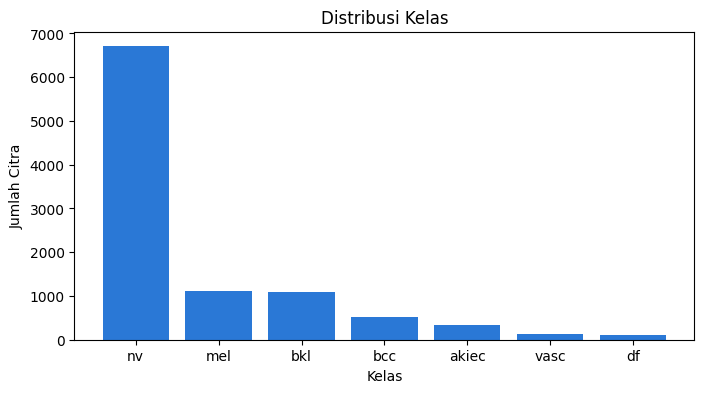

In [ ]:
class_counts = df['dx'].value_counts()
print(class_counts)
print(f'Rasio kelas terbesar : terkecil = {class_counts.max() / class_counts.min():.1f} : 1')
print(f'Akurasi jika selalu menebak kelas terbesar = {class_counts.max() / len(df):.1%}')

plt.figure(figsize=(8, 4))
plt.bar(class_counts.index, class_counts.values, color='#2a78d6')
plt.title('Distribusi Kelas')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Citra')
plt.show()

### Jumlah Citra per Lesi
Citra dari lesi yang sama sangat mirip, sehingga tidak boleh terpisah ke data latih dan data uji.

In [ ]:
images_per_lesion = df.groupby('lesion_id').size()
print(images_per_lesion.value_counts().sort_index())
print(f'Citra dari lesi yang memiliki lebih dari satu citra: {df["lesion_id"].map(images_per_lesion).gt(1).mean():.1%}')

1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64
Citra dari lesi yang memiliki lebih dari satu citra: 44.9%


### Usia, Jenis Kelamin, dan Lokasi Lesi

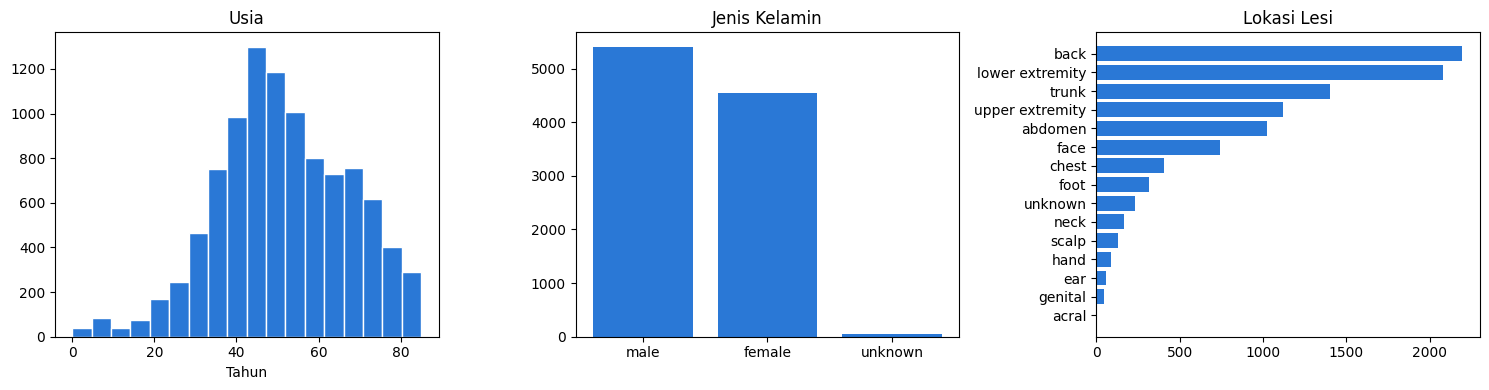

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df['age'].dropna(), bins=18, color='#2a78d6', edgecolor='white')
axes[0].set_title('Usia')
axes[0].set_xlabel('Tahun')

sex_counts = df['sex'].value_counts()
axes[1].bar(sex_counts.index, sex_counts.values, color='#2a78d6')
axes[1].set_title('Jenis Kelamin')

location_counts = df['localization'].value_counts().sort_values()
axes[2].barh(location_counts.index, location_counts.values, color='#2a78d6')
axes[2].set_title('Lokasi Lesi')

plt.tight_layout()
plt.show()

### Contoh Citra per Kelas

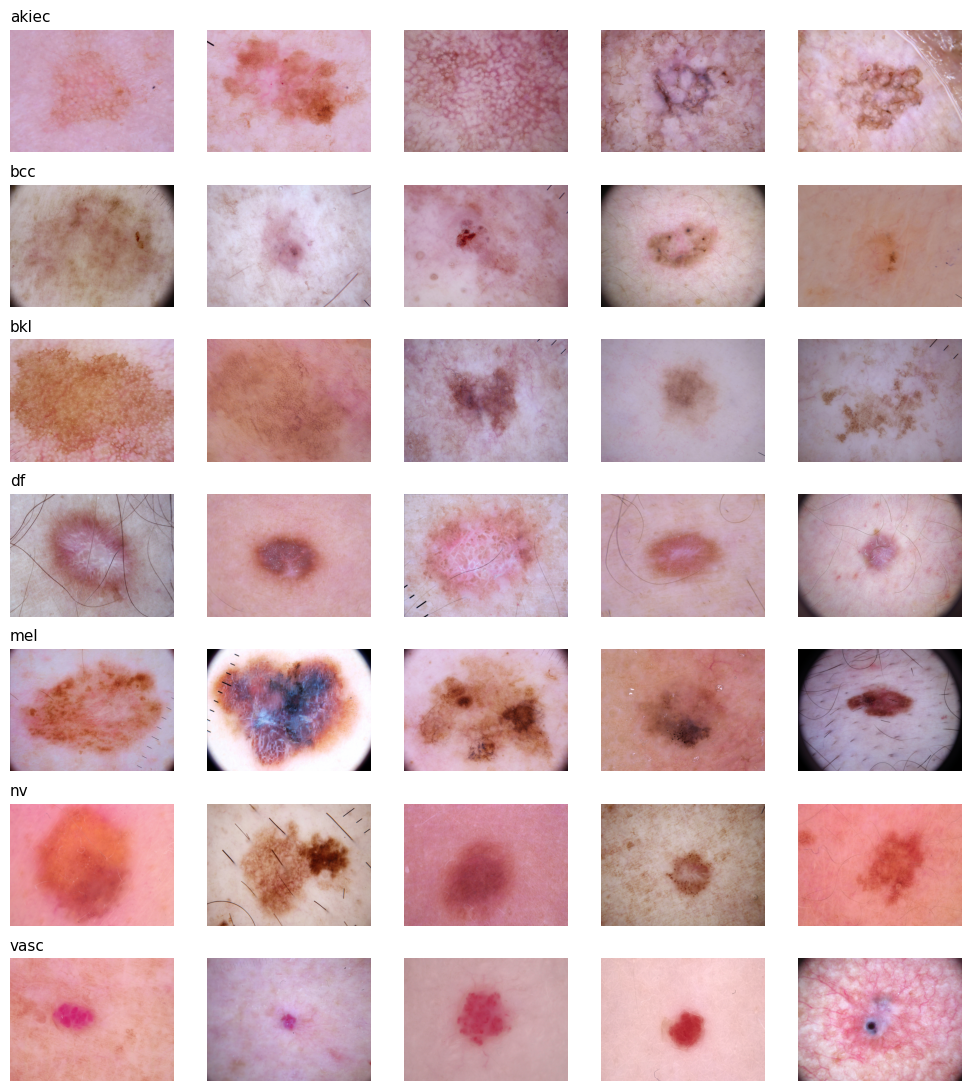

In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(10, 11))

for row, class_name in enumerate(CLASSES):
    samples = df[df['dx'] == class_name].sample(5, random_state=SEED)
    for col, path in enumerate(samples['path']):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].axis('off')
    axes[row, 0].set_title(class_name, loc='left', fontsize=11)

plt.tight_layout()
plt.show()

### Temuan EDA (A.3.f)
- Kelas `nv` mencakup 66,9% data dan rasio kelas terbesar terhadap terkecil adalah 58,3 : 1, sehingga macro F1 dipakai sebagai metrik utama dan focal loss diuji.
- Sebanyak 44,9% citra berasal dari lesi yang memiliki lebih dari satu citra, sehingga data dibagi berdasarkan `lesion_id`.
- Citra berukuran 600×450, sehingga perlu diresize ke 224×224 untuk MobileNetV2.
- Variasi posisi dan pencahayaan ditangani dengan augmentasi.

Word count (A.3.b), histogram fitur numerik (A.3.c), dan korelasi antarfitur (A.3.d) tidak berlaku karena data utamanya berupa citra.

## **Data Preprocessing**
### Pembersihan Data

In [ ]:
print('image_id duplikat:', df['image_id'].duplicated().sum())
print('Citra tidak ditemukan:', df['path'].isna().sum())
df = df.dropna(subset=['path']).drop_duplicates('image_id').reset_index(drop=True)

corrupt = []
for path in df['path']:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        corrupt.append(path)

print('Citra rusak:', len(corrupt))
df = df[~df['path'].isin(corrupt)].reset_index(drop=True)
df['label'] = df['dx'].map({name: index for index, name in enumerate(CLASSES)})
print('Citra yang dipakai:', len(df))

image_id duplikat: 0
Citra tidak ditemukan: 0
Citra rusak: 0
Citra yang dipakai: 10015


**Penjelasan (A.4.a, A.4.d):** Tidak ditemukan `image_id` duplikat, file hilang, atau citra rusak. Kesalahan label tidak dapat diperiksa langsung tanpa ahli, sedangkan `dx_type` menunjukkan cara diagnosis ditetapkan. Terdapat 57 nilai usia kosong, tetapi tidak diimputasi karena metadata bukan input model. Outlier pada metadata juga tidak memengaruhi model.

### Data Splitting
Data dibagi sekitar 70% latih, 15% validasi, dan 15% uji. `StratifiedGroupKFold` menjaga proporsi kelas dan memastikan satu lesi hanya berada di satu bagian.

In [ ]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_val_index, test_index = next(splitter.split(df, df['label'], df['lesion_id']))
train_val_df = df.iloc[train_val_index]
test_df = df.iloc[test_index].reset_index(drop=True)

splitter = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
train_index, val_index = next(splitter.split(train_val_df, train_val_df['label'], train_val_df['lesion_id']))
train_df = train_val_df.iloc[train_index].reset_index(drop=True)
val_df = train_val_df.iloc[val_index].reset_index(drop=True)

# Memastikan tidak ada kebocoran data
assert not set(train_df['lesion_id']) & set(val_df['lesion_id'])
assert not set(train_df['lesion_id']) & set(test_df['lesion_id'])
assert not set(val_df['lesion_id']) & set(test_df['lesion_id'])

print(f'Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}')
pd.DataFrame({
    'train': train_df['dx'].value_counts(),
    'validation': val_df['dx'].value_counts(),
    'test': test_df['dx'].value_counts(),
})

Train: 7145 | Validation: 1429 | Test: 1441


,train,validation,test
dx,,,
akiec,244,49,34
bcc,358,67,89
bkl,780,151,168
df,79,27,9
mel,814,153,146
nv,4769,962,974
vasc,101,20,21


**Penjelasan (A.4.e):** Data terbagi menjadi 7.145 citra latih, 1.429 validasi, dan 1.441 uji, atau sekitar 70/15/15. Pembagian berdasarkan `lesion_id` mencegah kebocoran data karena citra dari lesi yang sama tidak muncul di lebih dari satu bagian.

### Pipeline Dataset
Citra diresize ke 224×224. Rescale dan augmentasi berada di dalam model.

In [ ]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, tf.one_hot(label, NUM_CLASSES)

def make_dataset(data, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((data['path'].astype(str).tolist(), data['label'].to_numpy()))
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle:
        dataset = dataset.shuffle(len(data), seed=SEED)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = make_dataset(train_df, shuffle=True)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

**Penjelasan (A.4.b):** Citra diresize ke 224×224. Buffer `shuffle` dibuat sebesar seluruh data karena metadata tersusun per kelas. Tanpa pengacakan penuh, satu batch dapat didominasi kelas yang sama dan model cenderung bias ke kelas yang terakhir dilihat.

## **Penanganan Data Tidak Seimbang**
Focal loss memberi bobot lebih besar pada contoh yang sulit. Nilai `alpha` memberi bobot lebih besar pada kelas yang jumlahnya sedikit.

In [ ]:
class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_df['label'])
focal_alpha = np.sqrt(class_weights)
focal_alpha = focal_alpha / focal_alpha.mean()
focal_alpha = [float(value) for value in focal_alpha]

for name, alpha in zip(CLASSES, focal_alpha):
    print(f'{name:6s}: alpha = {alpha:.3f}')

akiec : alpha = 1.082
bcc   : alpha = 0.893
bkl   : alpha = 0.605
df    : alpha = 1.901
mel   : alpha = 0.592
nv    : alpha = 0.245
vasc  : alpha = 1.682


## **Modeling**
MobileNetV2 dipilih karena ringan, cepat dilatih, dan cukup cepat untuk melayani prediksi melalui FastAPI. `Rescaling` mengubah piksel ke rentang [-1, 1], sesuai kebutuhan MobileNetV2.

In [ ]:
def build_model():
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    model = keras.Sequential([
        keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        keras.layers.RandomFlip('horizontal_and_vertical'),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1),
        keras.layers.RandomContrast(0.1),

        keras.layers.Rescaling(1.0 / 127.5, offset=-1.0),
        base_model,
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(NUM_CLASSES, activation='softmax'),
    ])
    return model, base_model

build_model()[0].summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Penjelasan (A.4.b–c, A.5.a–b):** Model adalah CNN dengan transfer learning MobileNetV2. Piksel diubah ke [-1, 1] dengan `Rescaling`. Augmentasi yang aktif saat pelatihan adalah flip horizontal dan vertikal, rotasi 0,1, zoom 0,1, dan kontras 0,1. Layer Dense 128 memakai ReLU, Dropout 0,3 dipakai sebagai regularisasi, dan output softmax menghasilkan 7 kelas. Jumlah layer, ukuran output, dan parameter ada pada `summary()` di atas.

## **Training**
Setiap skenario dilatih dalam dua tahap:
1. MobileNetV2 dibekukan, lalu layer klasifikasi dilatih.
2. 30 layer terakhir MobileNetV2 dilatih ulang dengan learning rate lebih kecil.

Bobot terbaik dipilih berdasarkan macro F1 pada data validasi.

In [ ]:
def train_model(name, make_loss):
    keras.utils.set_random_seed(SEED)
    model, base_model = build_model()
    weights_path = os.path.join(OUTPUT_DIR, f'{name}.weights.h5')

    callbacks = [
        keras.callbacks.ModelCheckpoint(weights_path, monitor='val_macro_f1', mode='max',
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=5),
    ]
    metrics = lambda: ['accuracy', keras.metrics.F1Score(average='macro', name='macro_f1')]

    # Tahap 1
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=metrics())
    history_head = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS_HEAD, callbacks=callbacks)

    # Tahap 2
    model.load_weights(weights_path)
    base_model.trainable = True
    for layer in base_model.layers[:-UNFREEZE_LAST]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

    head_epochs = len(history_head.history['loss'])
    model.compile(optimizer=keras.optimizers.Adam(5e-5), loss=make_loss(), metrics=metrics())
    history_fine = model.fit(train_dataset, validation_data=val_dataset, initial_epoch=head_epochs,
                             epochs=head_epochs + EPOCHS_FINE, callbacks=callbacks)

    model.load_weights(weights_path)
    history = {key: history_head.history[key] + history_fine.history[key]
               for key in ('accuracy', 'val_accuracy', 'loss', 'val_loss', 'macro_f1', 'val_macro_f1')}
    return {'model': model, 'history': history,
            'val_probs': model.predict(val_dataset), 'test_probs': model.predict(test_dataset)}

**Konfigurasi pelatihan (A.5.c):**

| Parameter | Nilai |
|---|---|
| Optimizer | Adam |
| Learning rate | 0,001 (tahap 1), 0,00005 (tahap 2) |
| Batch size | 32 |
| Maksimum epoch | 8 (tahap 1), 12 (tahap 2) |
| Loss | Categorical cross-entropy dan focal loss (γ = 2) |
| Callback | ModelCheckpoint dan EarlyStopping (patience 5) berdasarkan macro F1 validasi |

### Skenario 1: Baseline (Cross-Entropy)

In [ ]:
baseline = train_model('baseline', lambda: keras.losses.CategoricalCrossentropy())

Epoch 1/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 81s 132ms/step - accuracy: 0.6890 - loss: 0.9331 - macro_f1: 0.2814 - val_accuracy: 0.7327 - val_loss: 0.7891 - val_macro_f1: 0.3524
Epoch 2/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.7232 - loss: 0.7954 - macro_f1: 0.3779 - val_accuracy: 0.7327 - val_loss: 0.7659 - val_macro_f1: 0.3927
Epoch 3/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.7351 - loss: 0.7440 - macro_f1: 0.4146 - val_accuracy: 0.7369 - val_loss: 0.7547 - val_macro_f1: 0.4212
Epoch 4/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - accuracy: 0.7370 - loss: 0.7296 - macro_f1: 0.4334 - val_accuracy: 0.7299 - val_loss: 0.7559 - val_macro_f1: 0.4200
Epoch 5/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.7460 - loss: 0.7098 - macro_f1: 0.4500 - val_accuracy: 0.7446 - val_loss: 0.7326 - val_macro_f1: 0.4379
Epoch 6/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.7540 - loss: 0.6916 - macro_f1: 0.4634 - val_accuracy: 0.7516 - val_loss: 0.7

### Skenario 2: Focal Loss

In [ ]:
focal = train_model('focal_loss', lambda: keras.losses.CategoricalFocalCrossentropy(alpha=focal_alpha, gamma=2.0))

Epoch 1/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 32s 118ms/step - accuracy: 0.6056 - loss: 0.4193 - macro_f1: 0.3154 - val_accuracy: 0.6865 - val_loss: 0.3294 - val_macro_f1: 0.3835
Epoch 2/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 22s 96ms/step - accuracy: 0.6655 - loss: 0.3186 - macro_f1: 0.4089 - val_accuracy: 0.7215 - val_loss: 0.3006 - val_macro_f1: 0.4475
Epoch 3/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - accuracy: 0.6746 - loss: 0.2868 - macro_f1: 0.4290 - val_accuracy: 0.7348 - val_loss: 0.3029 - val_macro_f1: 0.4433
Epoch 4/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - accuracy: 0.6862 - loss: 0.2762 - macro_f1: 0.4501 - val_accuracy: 0.7320 - val_loss: 0.2922 - val_macro_f1: 0.4702
Epoch 5/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 17s 76ms/step - accuracy: 0.6908 - loss: 0.2610 - macro_f1: 0.4758 - val_accuracy: 0.6802 - val_loss: 0.2677 - val_macro_f1: 0.4603
Epoch 6/8
224/224 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.6985 - loss: 0.2561 - macro_f1: 0.4902 - val_accuracy: 0.6984 - val_loss: 0.2

## **Plot Accuracy dan Loss**

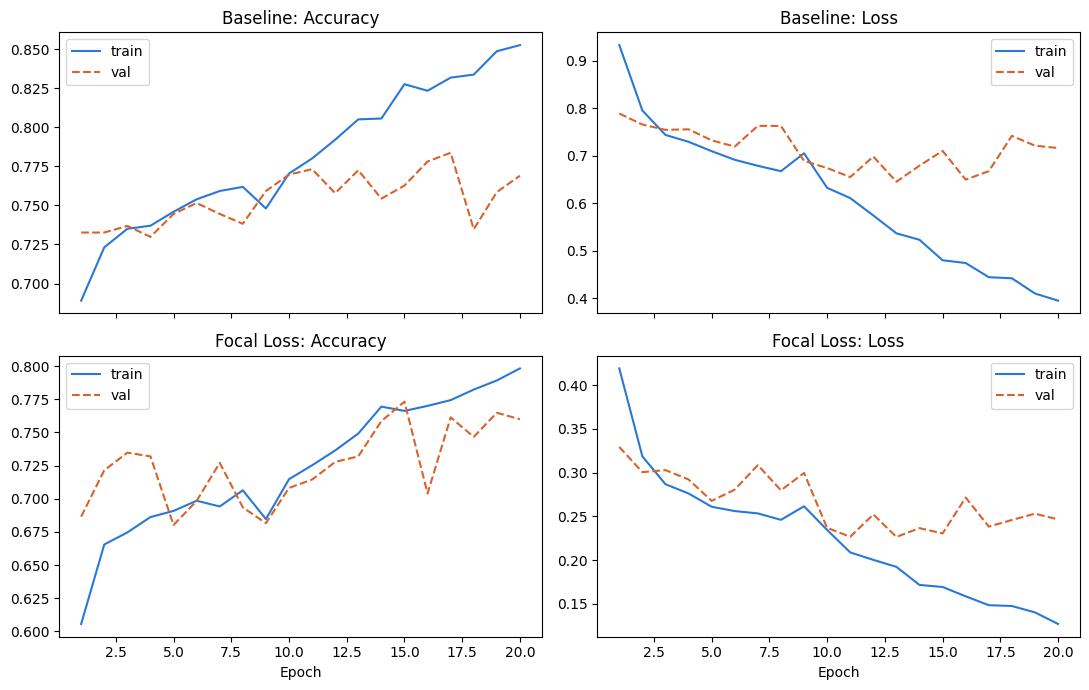

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex='col')

for row, (title, result) in enumerate({'Baseline': baseline, 'Focal Loss': focal}.items()):
    history = result['history']
    epochs = range(1, len(history['loss']) + 1)

    axes[row, 0].plot(epochs, history['accuracy'], color='#2a78d6', label='train')
    axes[row, 0].plot(epochs, history['val_accuracy'], color='#d9622b', linestyle='--', label='val')
    axes[row, 0].set_title(f'{title}: Accuracy')
    axes[row, 0].legend()

    axes[row, 1].plot(epochs, history['loss'], color='#2a78d6', label='train')
    axes[row, 1].plot(epochs, history['val_loss'], color='#d9622b', linestyle='--', label='val')
    axes[row, 1].set_title(f'{title}: Loss')
    axes[row, 1].legend()

axes[1, 0].set_xlabel('Epoch')
axes[1, 1].set_xlabel('Epoch')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'kurva_pelatihan.png'), dpi=200)
plt.show()

In [ ]:
gap = pd.DataFrame({
    title: {
        'accuracy_latih': result['history']['accuracy'][-1],
        'accuracy_validasi': result['history']['val_accuracy'][-1],
        'macro_f1_latih': result['history']['macro_f1'][-1],
        'macro_f1_validasi': result['history']['val_macro_f1'][-1],
    }
    for title, result in {'Baseline': baseline, 'Focal Loss': focal}.items()
}).T.round(4)
gap

,accuracy_latih,accuracy_validasi,macro_f1_latih,macro_f1_validasi
Baseline,0.8528,0.7691,0.7117,0.5759
Focal Loss,0.7983,0.7600,0.6998,0.5902


**Penjelasan (A.6.c, A.6.e):** Selisih besar antara nilai latih dan validasi, atau loss validasi yang naik saat loss latih turun, menandakan overfitting. Nilai latih dan validasi yang sama-sama rendah menandakan underfitting.

## **Perbandingan Skenario**
Model akhir dipilih berdasarkan macro F1 **validasi**. Data uji tidak dipakai untuk memilih model.

In [ ]:
y_val = val_df['label'].to_numpy()
y_test = test_df['label'].to_numpy()
melanoma_index = CLASSES.index('mel')

def score(y_true, probs):
    y_hat = probs.argmax(axis=1)
    return {
        'accuracy': accuracy_score(y_true, y_hat),
        'macro_f1': f1_score(y_true, y_hat, average='macro', zero_division=0),
        'recall_melanoma': recall_score(y_true, y_hat, labels=[melanoma_index], average='macro', zero_division=0),
    }

comparison = pd.DataFrame({
    'Baseline (validasi)': score(y_val, baseline['val_probs']),
    'Focal Loss (validasi)': score(y_val, focal['val_probs']),
    'Baseline (uji)': score(y_test, baseline['test_probs']),
    'Focal Loss (uji)': score(y_test, focal['test_probs']),
}).T.round(4)
comparison.to_csv(os.path.join(OUTPUT_DIR, 'perbandingan_skenario.csv'))

best_name = 'Focal Loss' if score(y_val, focal['val_probs'])['macro_f1'] > score(y_val, baseline['val_probs'])['macro_f1'] else 'Baseline'
best = focal if best_name == 'Focal Loss' else baseline
print('Model terpilih:', best_name)
comparison

Model terpilih: Focal Loss


,accuracy,macro_f1,recall_melanoma
Baseline (validasi),0.7691,0.5759,0.4575
Focal Loss (validasi),0.7733,0.5903,0.3660
Baseline (uji),0.7759,0.5655,0.4315
Focal Loss (uji),0.7738,0.5526,0.3767


**Penjelasan (A.5.e, A.6.d):** Tabel ini membandingkan model dengan dan tanpa focal loss, sekaligus menjadi bukti dampak fitur unik pertama. Tulis hasilnya apa adanya, termasuk jika focal loss tidak lebih baik.

## **Evaluasi pada Data Uji**

In [ ]:
test_probs = best['test_probs']
y_pred = test_probs.argmax(axis=1)
majority_class = train_df['label'].value_counts().idxmax()

print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'Macro F1 : {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'Accuracy jika selalu menebak kelas terbesar: {(y_test == majority_class).mean():.4f}')
print()
print(classification_report(y_test, y_pred, labels=np.arange(NUM_CLASSES), target_names=CLASSES, zero_division=0))

Accuracy : 0.7738
Macro F1 : 0.5526
Accuracy jika selalu menebak kelas terbesar: 0.6759

              precision    recall  f1-score   support

       akiec       0.35      0.26      0.30        34
         bcc       0.63      0.56      0.60        89
         bkl       0.50      0.71      0.59       168
          df       0.13      0.22      0.17         9
         mel       0.45      0.38      0.41       146
          nv       0.92      0.88      0.90       974
        vasc       0.87      0.95      0.91        21

    accuracy                           0.77      1441
   macro avg       0.55      0.57      0.55      1441
weighted avg       0.78      0.77      0.78      1441



**Penjelasan (A.6.a–b):** Accuracy mengukur prediksi benar secara keseluruhan, tetapi dapat menyesatkan pada data tidak seimbang. Precision mengukur ketepatan prediksi suatu kelas, recall mengukur banyaknya kasus kelas yang ditemukan, dan F1-score menyeimbangkan keduanya. Macro F1 menjadi metrik utama karena setiap kelas berbobot sama.

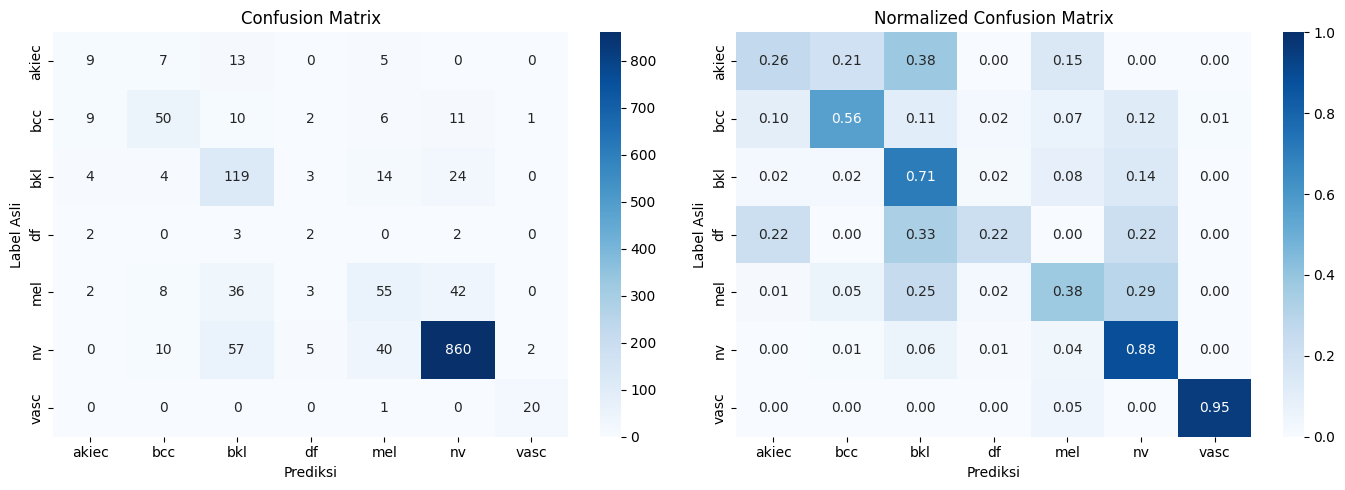

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title('Confusion Matrix')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix')

for ax in axes:
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label Asli')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=200)
plt.show()

In [ ]:
errors = pd.DataFrame(cm, index=CLASSES, columns=CLASSES).stack().reset_index()
errors.columns = ['asli', 'prediksi', 'jumlah']
errors = errors[errors['asli'] != errors['prediksi']]
errors.sort_values('jumlah', ascending=False).head(5)

,asli,prediksi,jumlah
37,nv,bkl,57
33,mel,nv,42
39,nv,mel,40
30,mel,bkl,36
19,bkl,nv,24


**Analisis hasil (A.6.e):** Kesalahan terbanyak adalah nv yang diprediksi sebagai bkl (57 citra), mel sebagai nv (42 citra), dan nv sebagai mel (40 citra). Sebanyak 29% citra mel diprediksi sebagai nv, kemungkinan karena kemiripan visual antara melanoma dan tahi lalat serta jumlah data nv yang jauh lebih banyak. Kelas df dan akiec memiliki recall rendah (0,22 dan 0,26), kemungkinan karena jumlah datanya sedikit. Model menunjukkan overfitting ringan hingga sedang: macro F1 akhir pada data latih 0,70 dan validasi 0,59, sedangkan loss validasi tidak lagi membaik setelah sekitar epoch 11 meskipun loss latih terus turun.

## **Confidence Threshold**
Prediksi dengan keyakinan di bawah ambang diberi tanda `low_confidence`. Sel ini menunjukkan dampaknya pada data uji.

In [ ]:
confidence = test_probs.max(axis=1)
confident = confidence >= CONFIDENCE_THRESHOLD

print(f'Accuracy semua prediksi      : {accuracy_score(y_test, y_pred):.4f}')
print(f'Accuracy prediksi yakin      : {accuracy_score(y_test[confident], y_pred[confident]):.4f}')
print(f'Accuracy prediksi tidak yakin: {accuracy_score(y_test[~confident], y_pred[~confident]) if (~confident).any() else float("nan"):.4f}')
print(f'Porsi prediksi yakin         : {confident.mean():.1%}')

Accuracy semua prediksi      : 0.7738
Accuracy prediksi yakin      : 0.8821
Accuracy prediksi tidak yakin: 0.4624
Porsi prediksi yakin         : 74.2%


**Penjelasan (A.5.e):** Ini fitur unik kedua. Prediksi di bawah ambang diberi tanda `low_confidence` agar website dapat memberi peringatan. Buktinya adalah perbedaan accuracy antara prediksi yakin dan tidak yakin.

## **Diagram Arsitektur (A.5.b)**

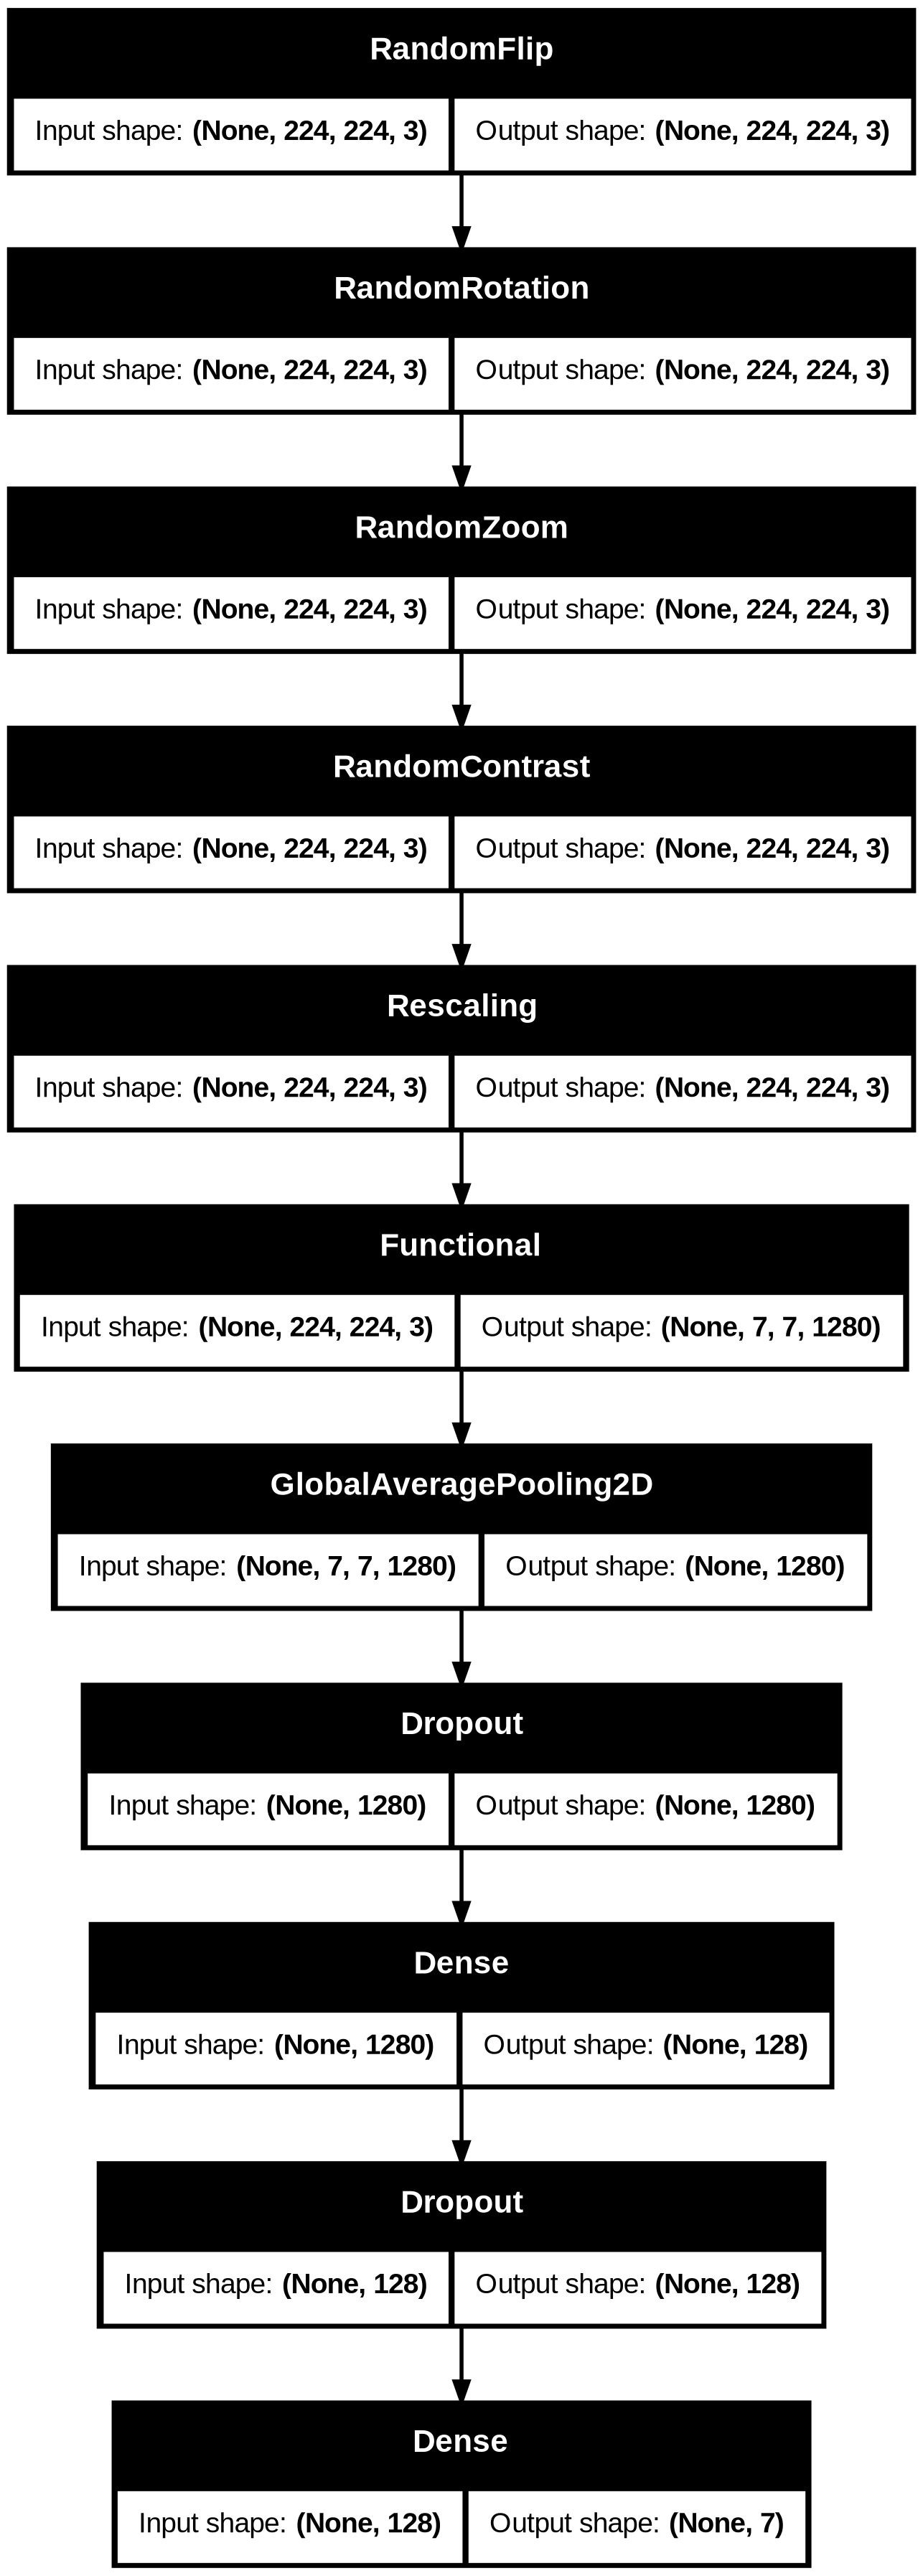

In [ ]:
keras.utils.plot_model(best['model'], to_file=os.path.join(OUTPUT_DIR, 'arsitektur_model.png'), show_shapes=True)

## **File Model untuk Deploy**

In [ ]:
DEPLOY_DIR = os.path.join(OUTPUT_DIR, 'model_deploy')
os.makedirs(DEPLOY_DIR, exist_ok=True)
MODEL_PATH = os.path.join(DEPLOY_DIR, 'model.keras')

best['model'].save(MODEL_PATH)

labels = {
    'classes': CLASSES,
    'class_names': CLASS_NAMES,
    'img_size': IMG_SIZE,
    'confidence_threshold': CONFIDENCE_THRESHOLD,
}
with open(os.path.join(DEPLOY_DIR, 'labels.json'), 'w') as file:
    json.dump(labels, file, indent=2)

with open(os.path.join(DEPLOY_DIR, 'requirements.txt'), 'w') as file:
    file.write(f'tensorflow-cpu=={tf.__version__}\nkeras=={keras.__version__}\n'
               'fastapi\nuvicorn\npython-multipart\npillow\nnumpy\n')

print(os.listdir(DEPLOY_DIR))
print(f'Ukuran model: {os.path.getsize(MODEL_PATH) / 1e6:.1f} MB')

['model.keras', 'labels.json', 'requirements.txt']
Ukuran model: 23.7 MB


## **Inference**
Sel ini memuat ulang `model.keras` dan memproses citra dari **bytes**, sama seperti file yang diterima FastAPI. Fungsi `predict_bytes` dapat langsung dipakai di backend.

In [ ]:
model = keras.models.load_model(MODEL_PATH, compile=False)

def predict_bytes(image_bytes):
    image = Image.open(io.BytesIO(image_bytes)).convert('RGB')
    array = tf.image.resize(np.array(image), (labels['img_size'], labels['img_size']))
    probs = model(tf.expand_dims(array, 0), training=False).numpy()[0]

    top3 = probs.argsort()[::-1][:3]
    best_index = int(top3[0])
    return {
        'label': CLASSES[best_index],
        'name': CLASS_NAMES[CLASSES[best_index]],
        'confidence': float(probs[best_index]),
        'low_confidence': bool(probs[best_index] < CONFIDENCE_THRESHOLD),
        'top3': [{'label': CLASSES[int(i)], 'confidence': float(probs[i])} for i in top3],
    }

**Penjelasan (A.8.a):** `predict_bytes` menerima file sebagai bytes, seperti unggahan di FastAPI. Fungsi ini hanya melakukan resize karena rescale sudah ada di dalam model.

In [ ]:
saved_pred = model.predict(test_dataset, verbose=0).argmax(axis=1)
print(f'Macro F1 model tersimpan: {f1_score(y_test, saved_pred, average="macro", zero_division=0):.4f}')
print(f'Kesamaan prediksi dengan evaluasi: {(saved_pred == y_pred).mean():.2%}')
assert (saved_pred == y_pred).mean() > 0.99

Macro F1 model tersimpan: 0.5526
Kesamaan prediksi dengan evaluasi: 100.00%


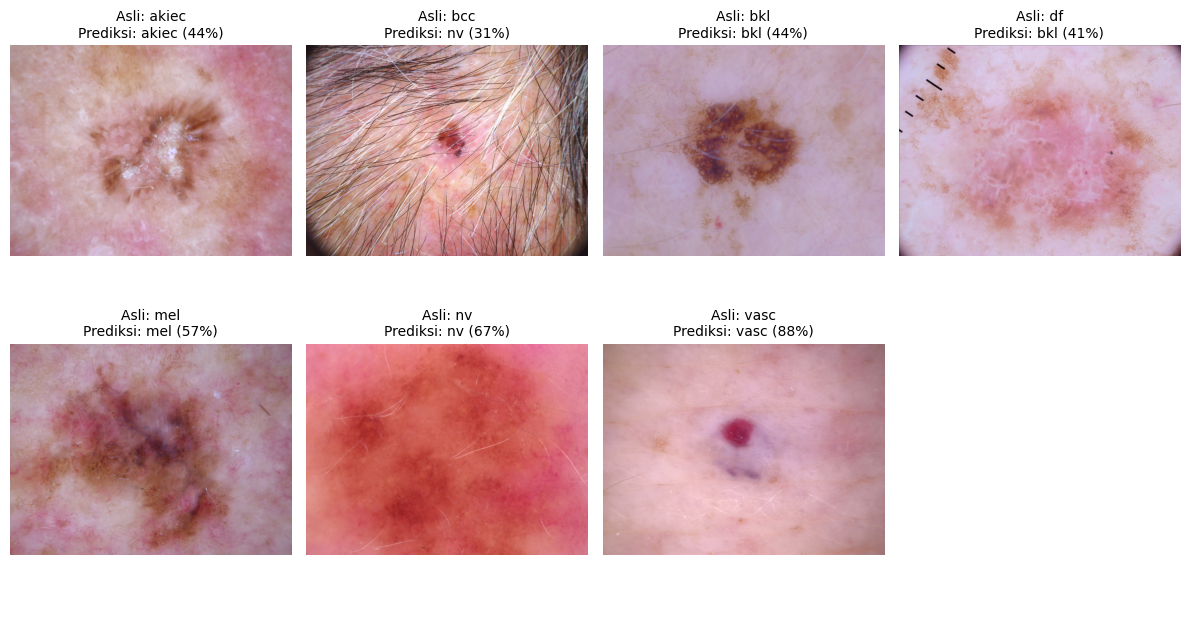

{
  "label": "vasc",
  "name": "Vascular lesions",
  "confidence": 0.876937210559845,
  "low_confidence": false,
  "top3": [
    {
      "label": "vasc",
      "confidence": 0.876937210559845
    },
    {
      "label": "mel",
      "confidence": 0.0437694787979126
    },
    {
      "label": "nv",
      "confidence": 0.039902739226818085
    }
  ]
}


In [ ]:
samples = test_df.groupby('dx').sample(1, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
axes = axes.ravel()
axes[-1].axis('off')

for ax, row in zip(axes, samples.itertuples()):
    with open(row.path, 'rb') as file:
        result = predict_bytes(file.read())
    ax.imshow(Image.open(row.path))
    ax.set_title(f"Asli: {row.dx}\nPrediksi: {result['label']} ({result['confidence']:.0%})", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()
print(json.dumps(result, indent=2))

## **Teknologi yang Digunakan (A.7)**

In [ ]:
import platform
from importlib.metadata import version

print('Python:', platform.python_version())
for package in ('tensorflow', 'keras', 'scikit-learn', 'numpy', 'pandas', 'matplotlib', 'seaborn', 'pillow', 'kagglehub'):
    print(f'{package}: {version(package)}')
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Python: 3.13.16
tensorflow: 2.21.0
keras: 3.13.2
scikit-learn: 1.6.1
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0
seaborn: 0.13.2
pillow: 11.3.0
kagglehub: 1.0.3
Tesla T4, 15360 MiB


- **Lingkungan (A.7.c):** Google Colab dengan GPU sesuai keluaran di atas.
- **Aplikasi (A.7.d):** Next.js, Echo (Go), dan FastAPI.
- **Hosting (A.7.d):** *[isi platform hosting]*

## **Lampiran (A.8)**
Kode penting ada pada `load_image`, `build_model`, `focal_alpha`, dan `predict_bytes`. Simpan grafik kurva pelatihan, confusion matrix, dan diagram arsitektur untuk lampiran.

## **Daftar Pustaka (A.9)**
1. Tschandl, P., Rosendahl, C., & Kittler, H. (2018). The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. *Scientific Data, 5*, 180161.
2. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. *CVPR*.
3. Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollár, P. (2017). Focal Loss for Dense Object Detection. *ICCV*.